# PRINCIPAL COMPONENT ANALYSIS (PCA)

## Loading and Visualizing the Olivetti Faces Dataset

a) Load the Olivetti Faces Dataset using sklearn.datasets.fetch_olivetti_faces.

b) Display a few random images from the dataset to understand the structure of the data.


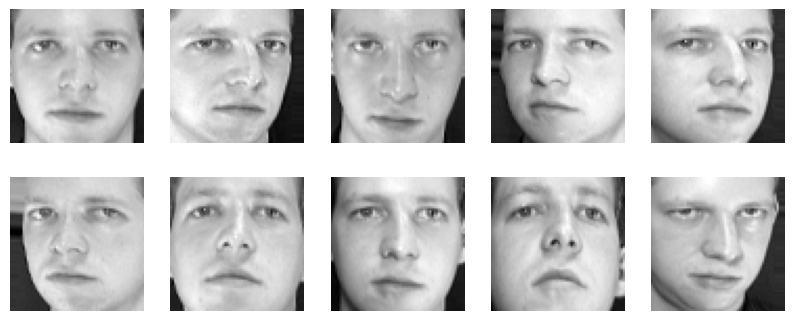

In [ ]:
from sklearn.datasets import fetch_olivetti_faces
import matplotlib.pyplot as plt
import numpy as np

# Load dataset
faces = fetch_olivetti_faces()
X, y = faces.data, faces.target

# Display a few sample images
fig, ax = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    ax[i // 5, i % 5].imshow(X[i].reshape(64, 64), cmap='gray')
    ax[i // 5, i % 5].axis('off')
plt.show()



## Performing PCA and Visualizing Principal Components
AIM: Understand how PCA transforms data and visualize the "eigenfaces" (principal components as images).

c) Apply PCA with a large number of components (e.g., 50) to capture most of the variance.

d) Display the first few principal components as "eigenfaces" to show what each principal component captures visually.

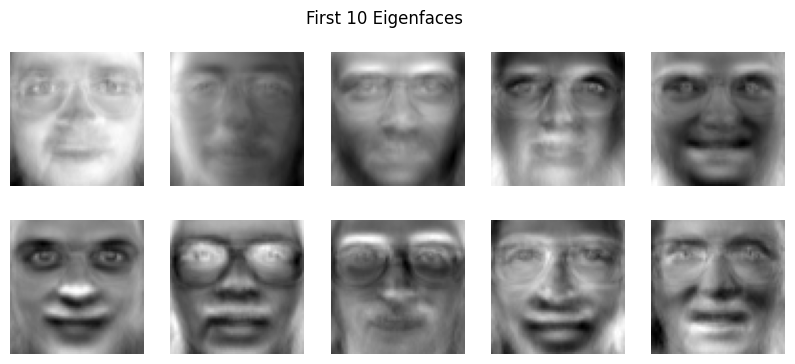

In [ ]:
from sklearn.decomposition import PCA

# Apply PCA
n_components = 50
pca = PCA(n_components=n_components, whiten=True)
X_pca = pca.fit_transform(X)

# Visualize the first 10 eigenfaces
fig, ax = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    ax[i // 5, i % 5].imshow(pca.components_[i].reshape(64, 64), cmap='gray')
    ax[i // 5, i % 5].axis('off')
plt.suptitle("First 10 Eigenfaces")
plt.show()


## Variance Explained by Principal Components

AIM: Identify the number of components needed to retain a significant amount of variance.

e) Plot the cumulative variance explained by each component.

f) Find the minimum number of components required to capture, say, 95% of the variance.

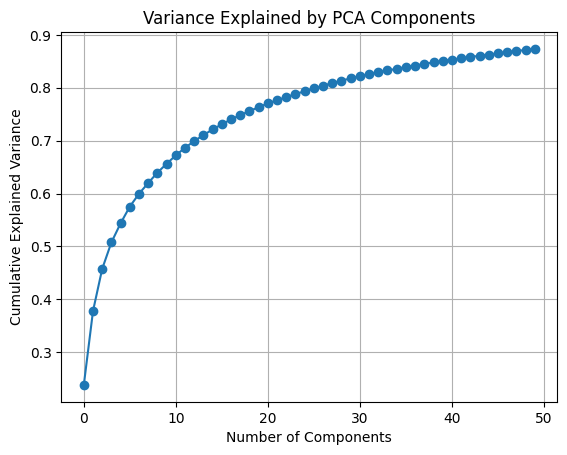

In [ ]:
# Cumulative explained variance plot
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
plt.plot(cumulative_variance, marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Variance Explained by PCA Components")
plt.grid()
plt.show()


## Reconstruction with Reduced Components
AIM: Understand the effect of dimensionality reduction on image quality.

g) Reconstruct a few images from PCA-transformed data using different numbers of components (e.g., 10, 50, 100).

h) Display and compare the reconstructed images to the original ones.

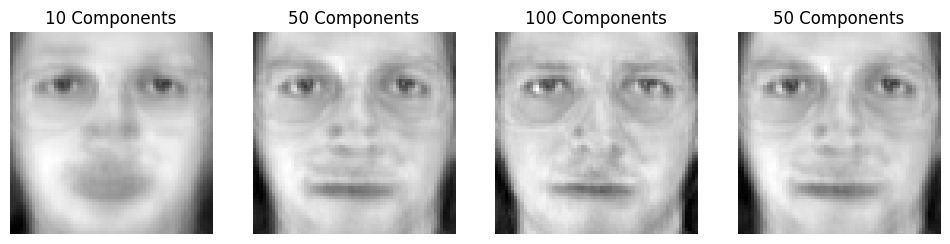

In [ ]:
# Reconstruct an image with different numbers of components
fig, ax = plt.subplots(1, 4, figsize=(12, 4))
components = [10, 50, 100, n_components]

for i, n in enumerate(components):
    pca_n = PCA(n_components=n, whiten=True).fit(X)
    X_pca_n = pca_n.transform(X)
    X_reconstructed = pca_n.inverse_transform(X_pca_n)
    ax[i].imshow(X_reconstructed[0].reshape(64, 64), cmap='gray')
    ax[i].set_title(f"{n} Components")
    ax[i].axis('off')
plt.show()


## PCA for Dimensionality Reduction and Classification

AIM: Explore the effect of PCA on classification accuracy using a simple linear classifier.

i) Apply PCA to reduce the data dimensionality, keeping 50 components.

j) Train a Logistic Regression classifier on the reduced dataset.

k) Evaluate and compare the classifier’s accuracy on the original vs. reduced datasets.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train on original data
clf_original = LogisticRegression(max_iter=1000)
clf_original.fit(X_train, y_train)
y_pred_original = clf_original.predict(X_test)
accuracy_original = accuracy_score(y_test, y_pred_original)

# Train on PCA-reduced data
pca = PCA(n_components=50, whiten=True, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

clf_pca = LogisticRegression(max_iter=1000)
clf_pca.fit(X_train_pca, y_train)
y_pred_pca = clf_pca.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print(f"Accuracy on original data: {accuracy_original * 100:.2f}%")
print(f"Accuracy on PCA-reduced data (50 components): {accuracy_pca * 100:.2f}%")


Accuracy on original data: 95.00%
Accuracy on PCA-reduced data (50 components): 93.33%


## Grid Search for Optimal Number of PCA Components

AIM: Find the optimal number of components for the best classification accuracy.

l) Use cross-validation to evaluate classifier accuracy for various numbers of PCA components (e.g., 10, 20, 50, 100).

m) Plot accuracy vs. the number of components to observe the impact of dimensionality on classification

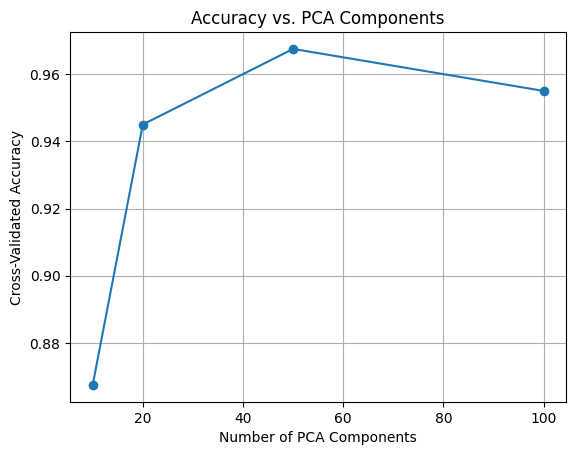

In [ ]:
from sklearn.model_selection import cross_val_score

# Test various numbers of PCA components
component_counts = [10, 20, 50, 100]
accuracies = []

for n in component_counts:
    pca_n = PCA(n_components=n, whiten=True)
    X_pca_n = pca_n.fit_transform(X)
    scores = cross_val_score(LogisticRegression(max_iter=1000), X_pca_n, y, cv=5)
    accuracies.append(scores.mean())

plt.plot(component_counts, accuracies, marker='o')
plt.xlabel("Number of PCA Components")
plt.ylabel("Cross-Validated Accuracy")
plt.title("Accuracy vs. PCA Components")
plt.grid()
plt.show()


# Exercise: Principal Component Analysis (PCA) and Classification Performance

In this exercise, you will apply PCA to reduce the dimensionality of the Olivetti Faces Dataset.

You will then train and test various classifiers on the PCA-reduced data.

The goal is to explore how different classifiers perform with different amounts of explained variance in PCA.

1) Load the Olivetti Faces Dataset.
2) Apply PCA with varying numbers of components to capture different levels of explained variance (e.g., 80%, 90%, and 95%).
3) For each level of explained variance, reduce the dataset's dimensionality using PCA and train the following classifiers on the transformed data:
- k-Nearest Neighbors (k-NN)
- Parzen Window Classifier (use Gaussian kernel density estimate)
- Logistic Regression

4) Compare the classification accuracy of each classifier across the different levels of explained variance.

5) Analyze and discuss:
5.1) Which classifier performs best with fewer PCA components and why?
5.2) How does the number of components (variance retained) affect each classifier’s performance?

1. First of all, let's load the Olivetti Faces Dataset

In [2]:
from sklearn.datasets import fetch_olivetti_faces
import numpy as np 

faces = fetch_olivetti_faces()
X, y = faces.data, faces.target

2. Now apply the PCA with varying numbers of components in order to capture different levels of explained variance, and visualize the first 10 eigenfaces for the different **variance**

In [4]:
from sklearn.decomposition import PCA

variance_levels = [0.80, 0.90, 0.95]

for val in variance_levels:
    pca = PCA(n_components=val)
    X_pca = pca.fit_transform(X)

    print(f"Per catturare il {val*100} della varianza servono {pca.n_components_} componenti.")

Per catturare il 80.0 della varianza servono 27 componenti.
Per catturare il 90.0 della varianza servono 66 componenti.
Per catturare il 95.0 della varianza servono 123 componenti.


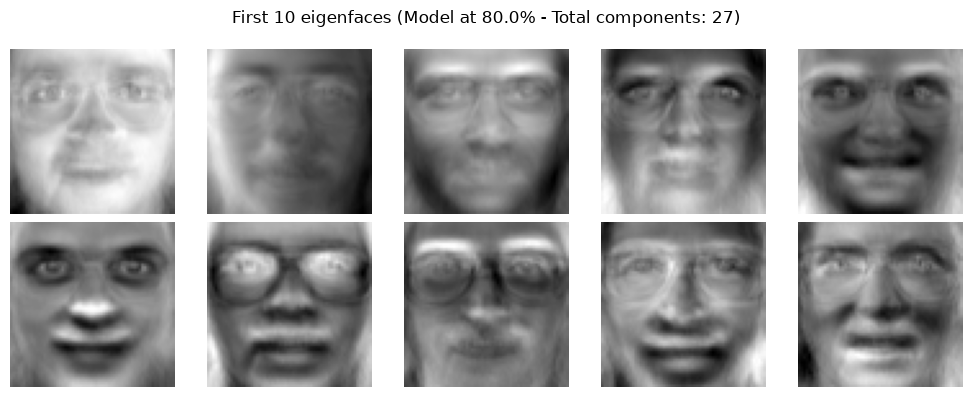

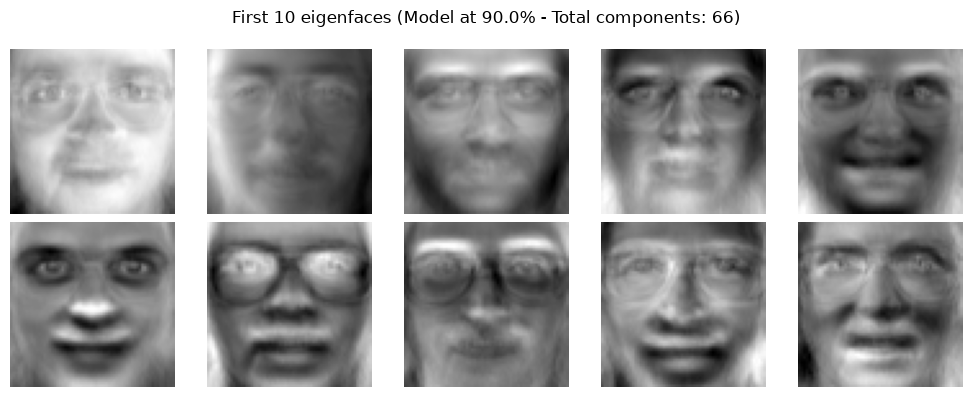

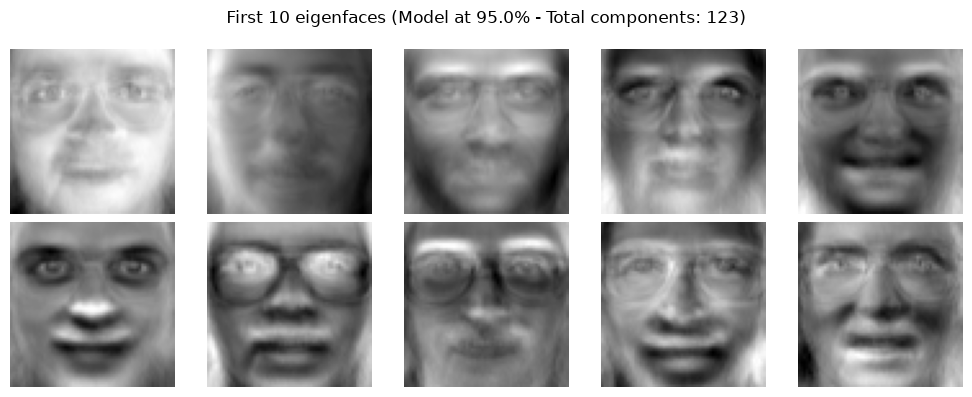

In [7]:
import matplotlib.pyplot as plt 

for val in variance_levels:

    pca = PCA(n_components=val)
    pca.fit(X)

    fig, ax = plt.subplots(2, 5, figsize=(10,4))


    for i in range(10):
        ax[i // 5, i % 5].imshow(pca.components_[i].reshape(64, 64), cmap='grey')
        ax[i // 5, i % 5].axis('off')


    plt.suptitle(f"First 10 eigenfaces (Model at {val*100}% - Total components: {pca.n_components_})")
    plt.tight_layout()
    plt.show()

3) For each level of explained variance, reduce the dataset's dimensionality using PCA and train the following classifiers on the transformed data:
    - k-Nearest Neighbors (k-NN)
    - Random Forest
    - Logistic Regression

=== Explained Variance: 0.80 (Components: 27) ===
k-NN Accuracy: 0.8875

Random Forest Accuracy: 0.7500

Logisitc Regression Accuracy: 0.9500

=== Explained Variance: 0.90 (Components: 66) ===
k-NN Accuracy: 0.8875

Random Forest Accuracy: 0.6875

Logisitc Regression Accuracy: 0.9750

=== Explained Variance: 0.95 (Components: 123) ===
k-NN Accuracy: 0.9250

Random Forest Accuracy: 0.6125

Logisitc Regression Accuracy: 0.9750



<function matplotlib.pyplot.show(close=None, block=None)>

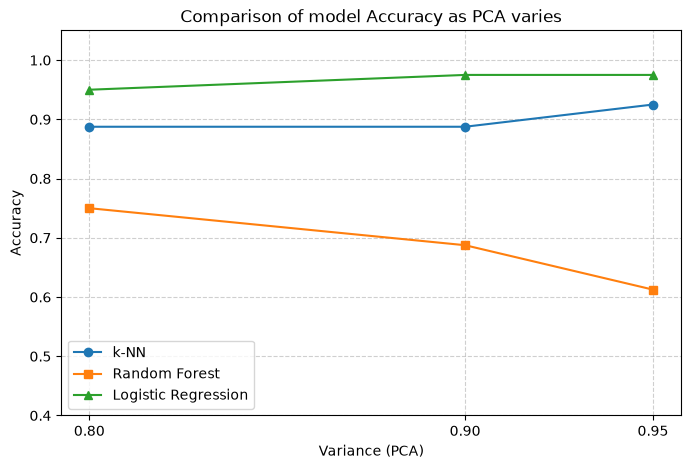

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA 
from sklearn.metrics import accuracy_score

variance_levels = [0.80, 0.90, 0.95]
n_neighbors = 1

acc_knn_list = []
acc_rf_list = []
acc_lr_list = []

for val in variance_levels: 

    pca = PCA(n_components=val)
    X_pca = pca.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size = 0.2, random_state = 42)

    # 1) KNN Classification 
    model = KNeighborsClassifier(n_neighbors)
    model.fit(X_train, y_train)
    pred_val_knn = model.predict(X_test)

    acc_knn = accuracy_score(y_test, pred_val_knn)
    acc_knn_list.append(acc_knn)

    # 2) RandomForest Classification
    rf = RandomForestClassifier(n_estimators=10, random_state=24)
    rf.fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)

    acc_rf = accuracy_score(y_test, y_pred_rf)
    acc_rf_list.append(acc_rf)

    # 3) Logistic Regression Classification
    lr = LogisticRegression(max_iter=1000, random_state=42)
    lr.fit(X_train, y_train)
    y_pred_lr = lr.predict(X_test)

    acc_lr = accuracy_score(y_test, y_pred_lr)
    acc_lr_list.append(acc_lr)

    print(f"=== Explained Variance: {val:.2f} (Components: {pca.n_components_}) ===")
    print(f"k-NN Accuracy: {acc_knn:.4f}\n")
    print(f"Random Forest Accuracy: {acc_rf:.4f}\n")
    print(f"Logisitc Regression Accuracy: {acc_lr:.4f}\n")

    
# Graphical visualization
plt.figure(figsize=(8,5))

plt.plot(variance_levels, acc_knn_list, marker='o', label='k-NN')
plt.plot(variance_levels, acc_rf_list, marker='s', label='Random Forest')
plt.plot(variance_levels, acc_lr_list, marker='^', label='Logistic Regression')

plt.title('Comparison of model Accuracy as PCA varies')
plt.xlabel('Variance (PCA)')
plt.ylabel('Accuracy')
plt.xticks(variance_levels)
plt.ylim(0.4, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.show


4) Compare the classification accuracy of each classifier across the different levels of explained variance.

### Summary of Results

| Explained Variance (PCA) | k-NN (low $k$) | Random Forest (`n_estimators=10`) | Logistic Regression (`max_iter=1000`) |
| :--- | :---: | :---: | :---: |
| **0.80** | 0.8875 | 0.7500 | 0.9500 |
| **0.90** | 0.8875 | 0.6875 | **0.9750** |
| **0.95** | **0.9250** | 0.6125 | **0.9750** |

### Key Observations

* **Logistic Regression (Best Overall Performance):**  
  Logistic Regression consistently outperforms the other classifiers across all variance levels, achieving **95.00%** accuracy at 0.80 variance and peaking at **97.50%** at 0.90 and 0.95. Retaining more principal components gives the linear model richer facial features to separate the 40 classes effectively without overfitting.

* **k-Nearest Neighbors (Strong Improvement with Low $k$):**  
  Since the Olivetti Faces dataset contains only 10 images per subject (around 8 in the training set), using a small number of neighbors prevents the algorithm from averaging across different individuals. With a low $k$, k-NN achieves **88.75%** at 0.80–0.90 variance and improves to **92.50%** at 0.95 variance, benefiting from the sharper local details preserved by higher PCA components.

* **Random Forest (Performance Drop at Higher Dimensionality):**  
  Random Forest reaches its highest accuracy at 0.80 variance (**75.00%**), but declines steadily as more components are retained (**68.75%** at 0.90 and **61.25%** at 0.95). With a small ensemble (`n_estimators=10`) and few training samples per class, higher-dimensional spaces make individual decision tree splits less effective.

#### 5.1 **Which classifier performs best with fewer PCA components and why?**

- **Answer**: **Logistic Regression** achieves the highest absolute accuracy even with fewer components (95.00% at 0.80 variance). However, looking at the trend, **Random Forest** is unique because it performs *best relative to its own scale* at lower dimensionality (75.00% at 0.80 variance), dropping as components increase.

- **Why**: Logistic Regression benefits immediately from PCA because the linear combinations of pixels cleanly separate the face classes in a global vector space even with fewer dimensions. For Random Forest, fewer components mean a less complex feature space, preventing individual axis-aligned decision tree from overfitting on noisy high-dimensional splits given the small number of training samples per class


#### 5.2 **How does the number of components (variance retained) affect each classifier's performance?**

The increase in explained variance (from 0.80 to 0.95) impacts the three classifier differently:

- **Logistic Regression (Improves/Stabilizes)**: Accuracy increases from **95.00%** to **97.50%** when moving from 0.80 to 0.90 variance, then plateaus. Retaining more components provides finer facial details and subtle variance that help the linear boundary separate classes more cleanly.

- **k-NN (Improves with Higher Variance)**: Accuracy increases noticeably at higher variance (reaching **92.50%** at 0.95). Distance-based metrics rely heavily on local geometric structures; retaining more principal components preserves sharper local details of the faces, making Euclidean distance measurements more accurate.

- **Random Forest (Decreases with Higher Variance)**: Accuracy steadily drops as variance increases (failing from **75.00%** down to **61.25%**). As the dimensionality grows, the feature space becomes sparser. With a small ensemble (`n_estimators`), individual decision trees struggle to find optimal split in higher dimensions, leading to degraded perfromance.